In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

X_train_enc = pd.read_csv('../data/X_train_enc.csv')
X_test_enc = pd.read_csv('../data/X_test_enc.csv')
y_train = pd.read_csv('../data/y_train.csv').squeeze()
y_test = pd.read_csv('../data/y_test.csv').squeeze()

xgb_model = joblib.load('../src/xgb_final_model.pkl')
logit_result = joblib.load('../src/logit_final_model.pkl')

print(X_train_enc.shape, X_test_enc.shape)

(800, 48) (200, 48)


In [2]:
xgb_probs = xgb_model.predict_proba(X_test_enc)[:, 1]

# The logistic model was fit with a constant column, so add it back
X_test_sm = sm.add_constant(X_test_enc.astype(float), has_constant='add')
logit_probs = np.asarray(logit_result.predict(X_test_sm))

print("XGBoost probs range:", xgb_probs.min(), xgb_probs.max())
print("Logit probs range:", logit_probs.min(), logit_probs.max())

XGBoost probs range: 0.014315894 0.9629109
Logit probs range: 0.005663607703607713 0.9217810039101009


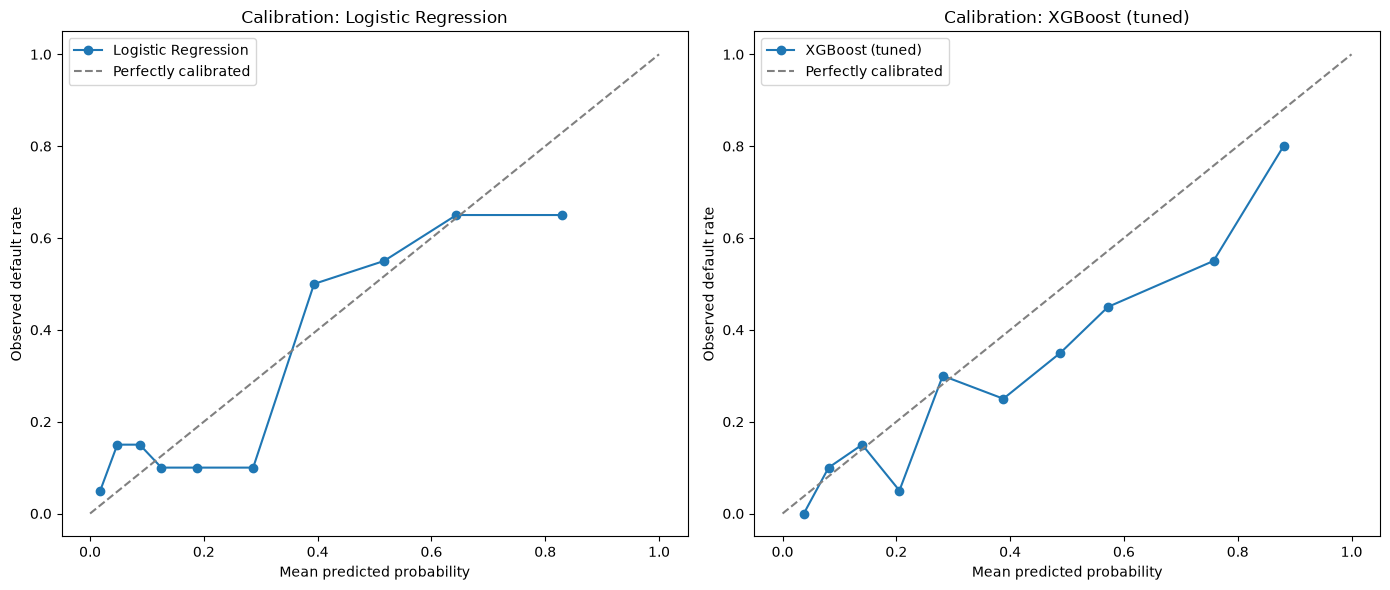

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, probs, name in zip(axes, [logit_probs, xgb_probs], ['Logistic Regression', 'XGBoost (tuned)']):
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10, strategy='quantile')
    ax.plot(prob_pred, prob_true, marker='o', label=name)
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
    ax.set_xlabel('Mean predicted probability')
    ax.set_ylabel('Observed default rate')
    ax.set_title(f'Calibration: {name}')
    ax.legend()

plt.tight_layout()
plt.savefig('../reports/figures/calibration_curves_raw.png', dpi=100)
plt.show()

In [4]:
print("Logistic Regression Brier Score:", brier_score_loss(y_test, logit_probs))
print("XGBoost Brier Score:", brier_score_loss(y_test, xgb_probs))

Logistic Regression Brier Score: 0.1576320266934058
XGBoost Brier Score: 0.1667184829711914


In [5]:
xgb_calibrated = CalibratedClassifierCV(xgb_model, method='isotonic', cv=5)
xgb_calibrated.fit(X_train_enc, y_train)
xgb_probs_calibrated = xgb_calibrated.predict_proba(X_test_enc)[:, 1]

print("XGBoost Brier Score (raw):", brier_score_loss(y_test, xgb_probs))
print("XGBoost Brier Score (calibrated):", brier_score_loss(y_test, xgb_probs_calibrated))

XGBoost Brier Score (raw): 0.1667184829711914
XGBoost Brier Score (calibrated): 0.1575306925463186


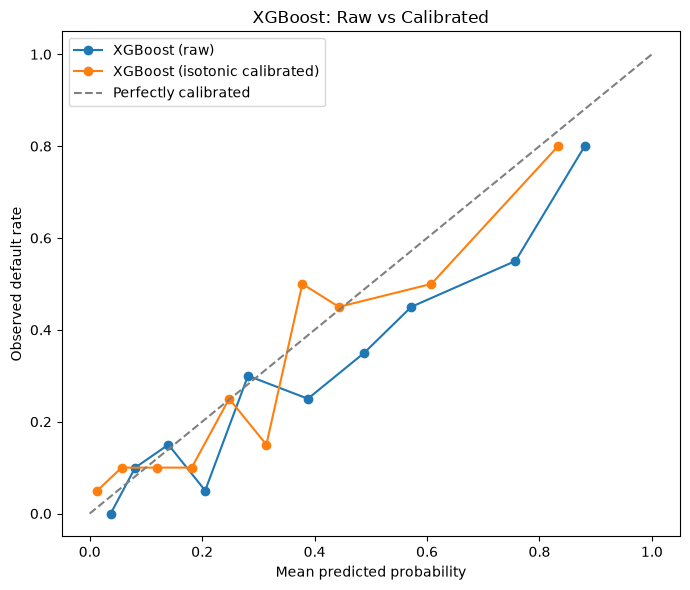

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))

prob_true_raw, prob_pred_raw = calibration_curve(y_test, xgb_probs, n_bins=10, strategy='quantile')
prob_true_cal, prob_pred_cal = calibration_curve(y_test, xgb_probs_calibrated, n_bins=10, strategy='quantile')

ax.plot(prob_pred_raw, prob_true_raw, marker='o', label='XGBoost (raw)')
ax.plot(prob_pred_cal, prob_true_cal, marker='o', label='XGBoost (isotonic calibrated)')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed default rate')
ax.set_title('XGBoost: Raw vs Calibrated')
ax.legend()

plt.tight_layout()
plt.savefig('../reports/figures/calibration_before_after.png', dpi=100)
plt.show()

In [7]:
saved_cal = joblib.load('../src/xgb_calibrated_model.pkl')
saved_cal_probs = saved_cal.predict_proba(X_test_enc)[:, 1]

print("Probabilities match saved calibrated model:", np.allclose(saved_cal_probs, xgb_probs_calibrated, atol=1e-6))
print("Max abs difference:", np.abs(saved_cal_probs - xgb_probs_calibrated).max())
print("Saved model Brier:", brier_score_loss(y_test, saved_cal_probs))

Probabilities match saved calibrated model: True
Max abs difference: 0.0
Saved model Brier: 0.1575306925463186
